<font size=10>**DATA COLLECTION & QUALITY**</font> <a class="anchor" id='title'></a>

**Master's in Data Science & Advanced Analytics - NOVA IMS (26/27)**

**Course**: *Data Stream Mining — Practical Assignment I (PA48)*

**Project**: *Weather Windows for Outdoor Races — Angra do Heroísmo vs Braga*

**Group PA48**
- Beatriz Marques 20231605
- Duarte Fernandes 20231619

**Question**: *Which city offers more reliable weather windows for recurring outdoor races?*

**Pipeline step**: This notebook reproduces **step 1** of `python src/practical_assignment.py --config config.yaml`: load the configuration and fetch the two hourly city streams. Quality reports and descriptive plots are additional inspection steps; they do not change the streams.

| Notebook | What it does |
|---|---|
| **01 — `01_data_collection_and_quality.ipynb`** | **Data collection and quality** |
| 02 — `02_target_and_features.ipynb` | Target, features and shared mask |
| 03 — `03_prequential_evaluation.ipynb` | Evaluation and audit outputs |
| 04 — `04_results_and_figures.ipynb` | Results, figures and audit checks |

<font color='#BFD72F' size=6>**TABLE OF CONTENTS**</font> <a class="anchor" id='toc'></a>

- [1. Imports](#1)

- [2. Configuration](#2)
    - [2.1 Assignment Card](#2_1)
    - [2.2 Cities, Period and Warm-up](#2_2)

- [3. Data Collection](#3)
    - [3.1 Angra do Heroísmo](#3_1)
    - [3.2 Braga](#3_2)

- [4. Data Quality](#4)
    - [4.1 Quality Report](#4_1)
    - [4.2 Descriptive Statistics](#4_2)
        - [Insights](#insights_1)

- [5. Stream Overview](#5)
    - [5.1 Daily Evolution](#5_1)
    - [5.2 Monthly profile](#5_2)
        - [Insights](#insights_2)

# <font color='#BFD72F' size=6>**1. Imports**</font> <a class="anchor" id="1"></a>

[Back to TOC](#toc)

In [1]:
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings('ignore')

In [2]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Get the absolute path of the source code folder
source_code_path = os.path.abspath('../src')

# Add the source code folder to sys.path
if source_code_path not in sys.path:
    sys.path.append(source_code_path)

from data_loader import ROOT, load_config, fetch_city, quality_report

# <font color='#BFD72F' size=6>**2. Configuration**</font> <a class="anchor" id="2"></a>

[Back to TOC](#toc)

Load **`config.yaml`**.

In [3]:
cfg = load_config(ROOT / 'config.yaml')
period = cfg['period']
warm_n = cfg['warmup']['n_hours']
raw_dir = ROOT / cfg['paths']['raw_data']

## <font color='#BFD72F' size=5>2.1 Assignment Card</font> <a class="anchor" id="2_1"></a>

[Back to TOC](#toc)

In [4]:
display(pd.Series(cfg['assignment'], name='value').to_frame())

,value
code,PA48
group,GroupYY
business_context,Outdoor Running Event Organiser
business_question,Which city offers more reliable weather window...
target,T6


## <font color='#BFD72F' size=5>2.2 Cities, Period and Warm-up</font> <a class="anchor" id="2_2"></a>

[Back to TOC](#toc)

In [5]:
setup_rows = []
for key in ('city_a', 'city_b'):
    c = cfg['cities'][key]
    setup_rows.append({
        'city_key': key, 'city': c['name'],
        'latitude': c['latitude'], 'longitude': c['longitude'],
        'start_date': period['start_date'], 'end_date': period['end_date'],
        'timezone': period['timezone'], 'warmup_hours': warm_n,
    })
display(pd.DataFrame(setup_rows))
data = {}

,city_key,city,latitude,longitude,start_date,end_date,timezone,warmup_hours
0,city_a,Angra do Heroismo,38.6539,-27.21839,2021-01-01,2026-09-30,UTC,720
1,city_b,Braga,41.5514,-8.42311,2021-01-01,2026-09-30,UTC,720


# <font color='#BFD72F' size=6>**3. Data Collection**</font> <a class="anchor" id="3"></a>

[Back to TOC](#toc)

**`fetch_city`** caches each hourly stream as a CSV in the configured raw directory.

## <font color='#BFD72F' size=5>3.1 Angra do Heroísmo</font> <a class="anchor" id="3_1"></a>

[Back to TOC](#toc)

Fetch **`cfg["cities"]["city_a"]`** with `fetch_city`, using the configured coordinates, period and timezone. Inspect the shape, first rows and column types.

In [6]:
c = cfg['cities']['city_a']
data['city_a'] = fetch_city(
    c['name'], c['latitude'], c['longitude'],
    period['start_date'], period['end_date'], period['timezone'],
    raw_dir=raw_dir,
)
print(f"{c['name']}: shape={data['city_a'].shape}")
display(data['city_a'].head())
display(data['city_a'].dtypes.rename('dtype').to_frame())

Angra do Heroismo: shape=(50376, 5)


,time,temperature,relative_humidity,precipitation,wind_speed
0,2021-01-01 00:00:00,13.6,82,0.0,12.6
1,2021-01-01 01:00:00,13.6,83,0.0,13.4
2,2021-01-01 02:00:00,13.5,84,0.0,12.6
3,2021-01-01 03:00:00,13.3,86,0.0,12.6
4,2021-01-01 04:00:00,13.3,88,0.0,12.8


,dtype
time,datetime64[us]
temperature,float64
relative_humidity,int64
precipitation,float64
wind_speed,float64


## <font color='#BFD72F' size=5>3.2 Braga</font> <a class="anchor" id="3_2"></a>

[Back to TOC](#toc)

Fetch **`cfg["cities"]["city_b"]`** with `fetch_city`, using the configured coordinates, period and timezone. Inspect the shape, first rows and column types.

In [7]:
c = cfg['cities']['city_b']
data['city_b'] = fetch_city(
    c['name'], c['latitude'], c['longitude'],
    period['start_date'], period['end_date'], period['timezone'],
    raw_dir=raw_dir,
)
print(f"{c['name']}: shape={data['city_b'].shape}")
display(data['city_b'].head())
display(data['city_b'].dtypes.rename('dtype').to_frame())

Braga: shape=(50376, 5)


,time,temperature,relative_humidity,precipitation,wind_speed
0,2021-01-01 00:00:00,3.6,93,0.0,6.6
1,2021-01-01 01:00:00,2.3,93,0.0,6.9
2,2021-01-01 02:00:00,0.9,94,0.0,9.2
3,2021-01-01 03:00:00,1.0,94,0.0,8.0
4,2021-01-01 04:00:00,3.3,91,0.0,4.8


,dtype
time,datetime64[us]
temperature,float64
relative_humidity,int64
precipitation,float64
wind_speed,float64


# <font color='#BFD72F' size=6>**4. Data Quality**</font> <a class="anchor" id="4"></a>

[Back to TOC](#toc)

## <font color='#BFD72F' size=5>4.1 Quality Report</font> <a class="anchor" id="4_1"></a>

[Back to TOC](#toc)

In [8]:
quality_rows = []
for key, df in data.items():
    report = quality_report(df)
    row = {'city': cfg['cities'][key]['name']}
    row.update({k: v for k, v in report.items() if k != 'missing'})
    row.update({f'missing_{column}': count for column, count in report['missing'].items()})
    quality_rows.append(row)
display(pd.DataFrame(quality_rows))

,city,n_rows,start,end,duplicated_timestamps,irregular_steps,humidity_out_of_range,negative_precipitation,negative_wind,missing_time,missing_temperature,missing_relative_humidity,missing_precipitation,missing_wind_speed
0,Angra do Heroismo,50376,2021-01-01 00:00:00,2026-09-30 23:00:00,0,0,0,0,0,0,0,0,0,0
1,Braga,50376,2021-01-01 00:00:00,2026-09-30 23:00:00,0,0,0,0,0,0,0,0,0,0


## <font color='#BFD72F' size=5>4.2 Descriptive Statistics</font> <a class="anchor" id="4_2"></a>

[Back to TOC](#toc)

In [9]:
variables = ['temperature', 'relative_humidity', 'precipitation', 'wind_speed']
statistics = pd.concat(
    {cfg['cities'][key]['name']: df[variables].describe() for key, df in data.items()},
    axis=1,
)
display(statistics)

Angra do Heroismo                                                \
            temperature relative_humidity precipitation    wind_speed   
count      50376.000000      50376.000000  50376.000000  50376.000000   
mean          17.497479         85.308024      0.209364     13.696103   
std            3.644027         10.944584      0.679224      8.429235   
min            6.200000         46.000000      0.000000      0.000000   
25%           14.800000         77.000000      0.000000      6.900000   
50%           17.100000         87.000000      0.000000     12.400000   
75%           20.200000         95.000000      0.100000     19.100000   
max           29.300000        100.000000     19.700000     58.400000   

              Braga                                                
        temperature relative_humidity precipitation    wind_speed  
count  50376.000000      50376.000000  50376.000000  50376.000000  
mean      15.526648         76.441599      0.201106      8.955739  
std        6.437786         17.662954      0.764589      5.766255  
min       -3.900000         13.000000      0.000000      0.000000  
25%       11.200000         64.000000      0.000000      4.700000  
50%       15.100000         81.000000      0.000000      7.600000  
75%       19.300000         92.000000      0.000000     12.100000  
max       39.000000        100.000000     18.300000     46.800000

# <font color='#BFD72F' size=6>**5. Stream Overview**</font> <a class="anchor" id="5"></a>

[Back to TOC](#toc)

## <font color='#BFD72F' size=5>5.1 Daily Evolution</font> <a class="anchor" id="5_1"></a>

[Back to TOC](#toc)

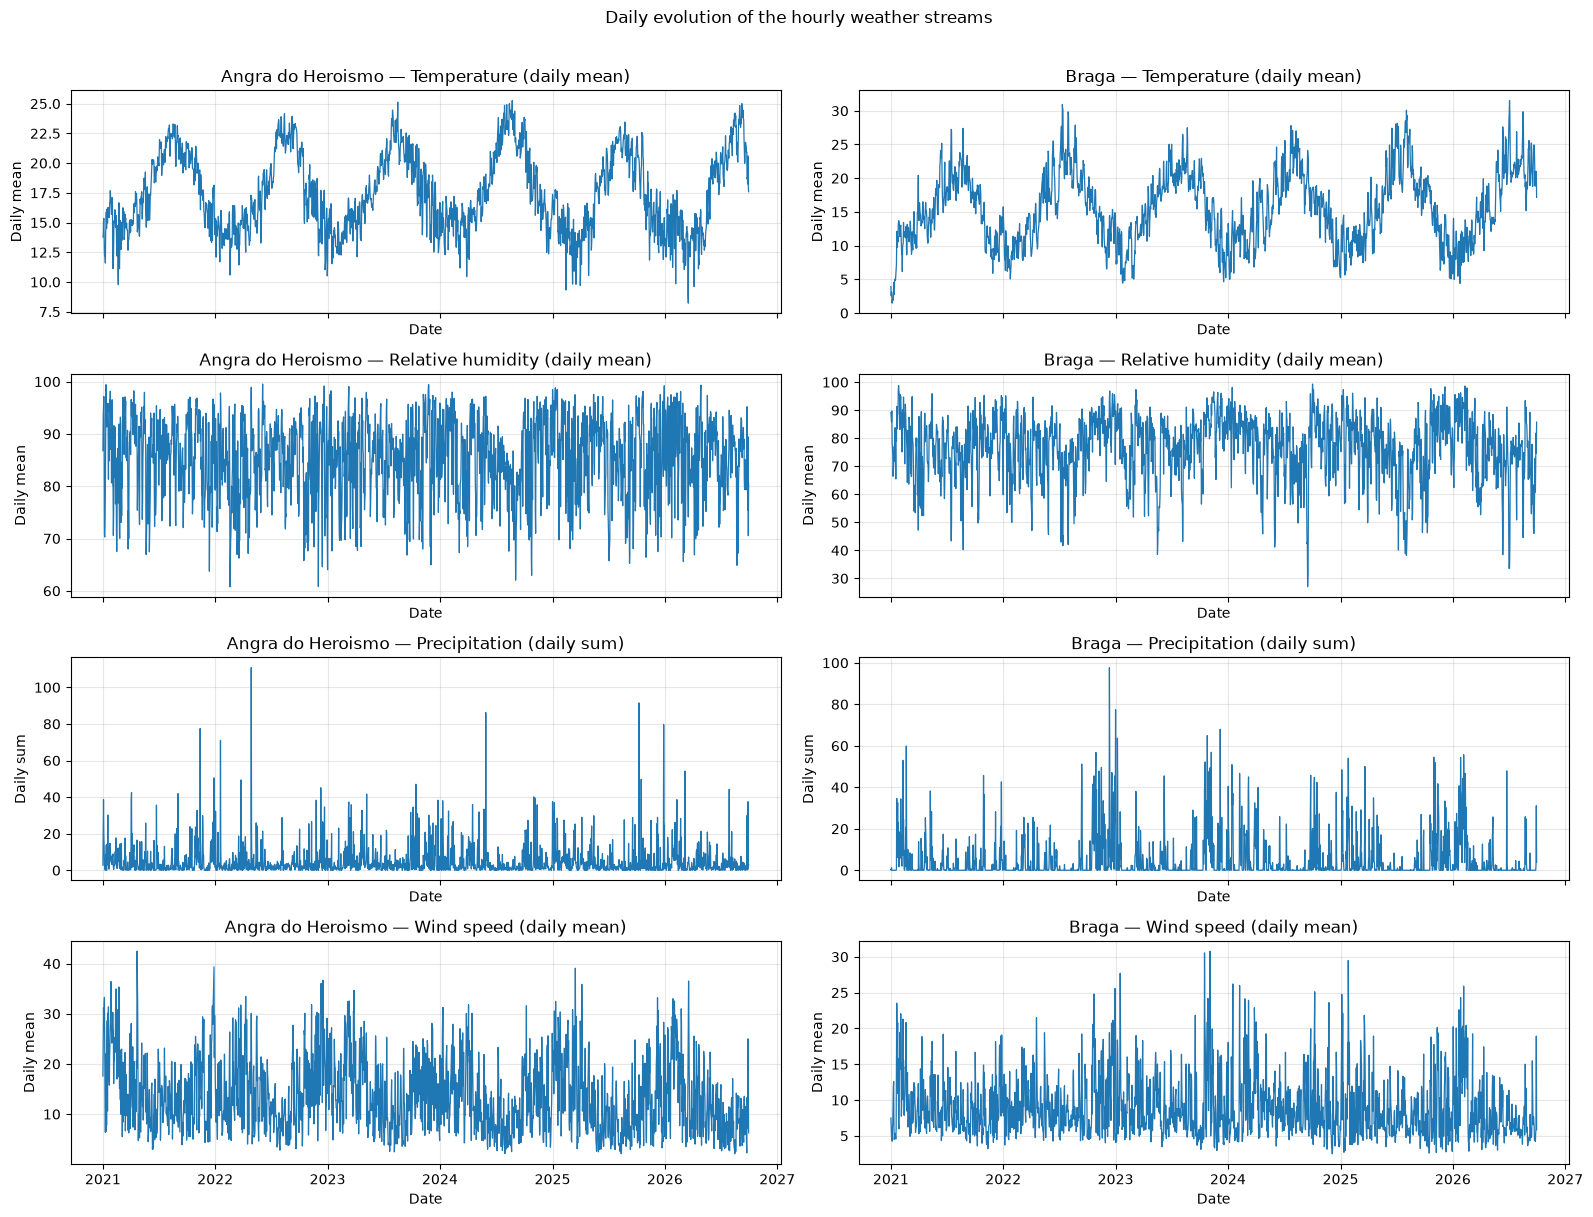

In [10]:
labels = {
    'temperature': 'Temperature', 'relative_humidity': 'Relative humidity',
    'precipitation': 'Precipitation', 'wind_speed': 'Wind speed',
}
aggregations = {
    'temperature': 'mean', 'relative_humidity': 'mean',
    'precipitation': 'sum', 'wind_speed': 'mean',
}
fig, axes = plt.subplots(4, 2, figsize=(16, 12), sharex='col', squeeze=False)
for j, key in enumerate(('city_a', 'city_b')):
    hourly = data[key].set_index('time')[variables]
    daily = hourly.resample('D').agg(aggregations)
    for i, variable in enumerate(variables):
        ax = axes[i, j]
        ax.plot(daily.index, daily[variable], linewidth=0.9)
        statistic = 'sum' if variable == 'precipitation' else 'mean'
        ax.set_title(f"{cfg['cities'][key]['name']} — {labels[variable]} (daily {statistic})")
        ax.set_ylabel(f'Daily {statistic}')
        ax.set_xlabel('Date')
        ax.grid(alpha=0.3)
fig.suptitle('Daily evolution of the hourly weather streams', y=1.01)
fig.tight_layout()
plt.show()

## <font color='#BFD72F' size=5>5.2 Monthly profile</font> <a class="anchor" id="5_2"></a>

[Back to TOC](#toc)

Angra do Heroismo                                             \
                     temperature relative_humidity precipitation wind_speed   
calendar_month                                                                
1                      14.718324         87.637545      0.282863  18.081855   
2                      14.333925         85.244083      0.233629  17.544798   
3                      14.014158         83.344982      0.200963  16.742159   
4                      14.896574         85.810185      0.270532  16.476991   
5                      16.439606         86.641129      0.237254  12.129973   
6                      18.898194         86.499306      0.119306  10.344977   
7                      21.005556         84.843638      0.117742   9.206541   
8                      22.488866         83.540099      0.122558   8.652128   
9                      21.280370         83.281250      0.155486  10.826458   
10                     19.370538         85.082527      0.257581  13.940860   
11                     17.108222         86.723889      0.275333  15.322833   
12                     15.036210         85.259409      0.269489  16.076909   

                     Braga                                             
               temperature relative_humidity precipitation wind_speed  
calendar_month                                                         
1                 8.931384         81.879480      0.344915  10.002890  
2                10.566889         79.479783      0.292604   9.865582  
3                11.731989         75.813620      0.192518   9.912074  
4                14.309907         74.363657      0.165810   8.764144  
5                16.392787         74.203181      0.128047   8.748185  
6                19.804190         74.826852      0.102523   8.095440  
7                22.088172         68.676523      0.030824   8.232818  
8                22.194556         70.070116      0.034789   7.584140  
9                19.164699         74.126852      0.155185   8.155278  
10               16.975699         80.638710      0.414005   9.497070  
11               12.492278         82.934722      0.299750   9.249667  
12               10.195726         83.502688      0.331102   9.647366

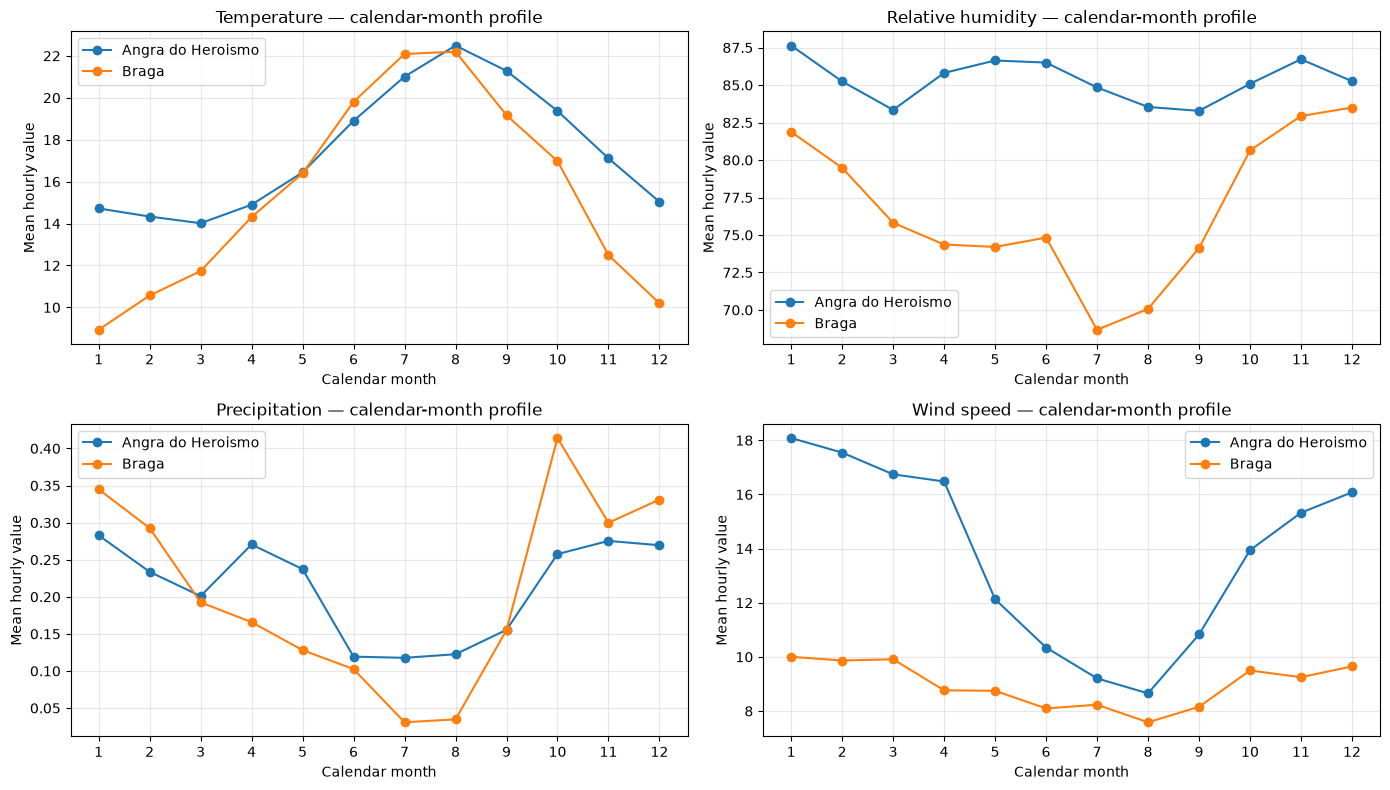

In [11]:
monthly_profiles = {}
for key, df in data.items():
    monthly_profiles[cfg['cities'][key]['name']] = (
        df.groupby(df['time'].dt.month)[variables].mean().reindex(range(1, 13))
    )
display(pd.concat(monthly_profiles, axis=1).rename_axis('calendar_month'))
fig, axes = plt.subplots(2, 2, figsize=(14, 8), squeeze=False)
for ax, variable in zip(axes.flat, variables):
    for city, profile in monthly_profiles.items():
        ax.plot(profile.index, profile[variable], marker='o', label=city)
    ax.set_title(f'{labels[variable]} — calendar-month profile')
    ax.set_xlabel('Calendar month')
    ax.set_ylabel('Mean hourly value')
    ax.set_xticks(range(1, 13))
    ax.legend()
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()